# TrendPulse — Part 3: Visualization, EDA & Business Thinking

A structured exploratory analysis of three countries of daily YouTube trending lists (US, GB, IN), ending in a short
**content strategy briefing** for a media-analytics team. All data is read from this folder's `data/` subfolder.

**Sections**
1. Profile and clean the data
2. Chart basics (Matplotlib, 6 charts)
3. Interactive charts (Plotly, 2 charts)
4. Distributions and outliers
5. Correlation
6. Funnel analysis
7. Retention-style analysis (trending lifespan)
8. Cohort view
9. Content strategy briefing

Every chart is followed by its interpretation and a sentence on why that chart type fits the variables.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import plotly.express as px
import plotly.io as pio

try:
    import google.colab  # noqa: F401  (Colab has its own Plotly renderer)
except ImportError:
    pio.renderers.default = "notebook_connected"

pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR, CHART_DIR = "data", "charts"
os.makedirs(CHART_DIR, exist_ok=True)
COUNTRIES = ["US", "GB", "IN"]

# one consistent, colour-blind-checked palette: a colour always means the same country / group
COUNTRY_COLORS = {"US": "#2a78d6", "GB": "#eb6834", "IN": "#1baf7a"}
SEQ = "#2a78d6"            # single hue for plain magnitudes
OTHER = "#b8b7b0"          # neutral grey for "everything else"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(f"{CHART_DIR}/{name}.png", bbox_inches="tight")
    plt.show()

## 1. Profile and clean the data

In [2]:
frames = []
for c in COUNTRIES:
    d = pd.read_csv(f"{DATA_DIR}/{c}videos.csv")
    d["country"] = c
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
categories = pd.read_csv(f"{DATA_DIR}/categories.csv")

print("shape:", raw.shape)
print(raw.groupby("country").size().rename("rows"))
print()
print(raw.dtypes)

shape: (46230, 17)
country
GB    15075
IN    15075
US    16080
Name: rows, dtype: int64

video_id                   object
trending_date              object
title                      object
channel_title              object
category_id                 int64
publish_time               object
tags                       object
views                       int64
likes                     float64
dislikes                    int64
comment_count             float64
thumbnail_link             object
comments_disabled            bool
ratings_disabled             bool
video_error_or_removed       bool
description                object
country                    object
dtype: object


In [3]:
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["percent"] = (missing["missing"] / len(raw) * 100).round(3)
missing

,missing,percent
likes,12,0.03
comment_count,36,0.08
description,1624,3.51


### Cleaning steps
1. Parse `trending_date` (`yy.dd.mm` text) and `publish_time` (ISO UTC) to datetimes.
2. Drop **duplicates** — the same `video_id` on the same `trending_date` in the same `country`.
3. Drop records of **removed / errored** videos (`video_error_or_removed`), whose statistics are invalid.
4. Drop the few records with a blank `likes` or `comment_count` (≈0.1% of rows — far too few to change any distribution, and
   imputing them would add invented values to the outlier and correlation work).
5. `description` blanks → `""` (text only, not analysed).
6. Attach `category_name` with a **left** merge on `category_id` and check that no record is lost.
7. Add `days_to_trend` = trending date − publish date, in days.

In [4]:
df = raw.copy()
df["trending_date"] = pd.to_datetime(df["trending_date"], format="%y.%d.%m")
df["publish_time"] = pd.to_datetime(df["publish_time"], utc=True).dt.tz_convert(None)

steps = [("raw", len(df))]
df = df.drop_duplicates(subset=["country", "video_id", "trending_date"])
steps.append(("after removing duplicates", len(df)))
df = df[~df["video_error_or_removed"]]
steps.append(("after removing removed/errored videos", len(df)))
df = df.dropna(subset=["likes", "comment_count"])
steps.append(("after dropping blank likes/comment_count", len(df)))
df["description"] = df["description"].fillna("")
df[["likes", "comment_count"]] = df[["likes", "comment_count"]].astype("int64")

n = len(df)
df = df.merge(categories, on="category_id", how="left", validate="many_to_one")
assert len(df) == n and df["category_name"].notna().all()
df["days_to_trend"] = (df["trending_date"] - df["publish_time"].dt.normalize()).dt.days

for label, rows in steps:
    print(f"{label:<44} {rows:>7,}")
print(f"\nclean shape: {df.shape}; records lost in category merge: {n - len(df)}")

raw                                           46,230
after removing duplicates                     46,000
after removing removed/errored videos         45,908
after dropping blank likes/comment_count      45,860

clean shape: (45860, 19); records lost in category merge: 0


**Unique videos.** Many questions are about *videos*, not daily records (a video that trends for 10 days has 10 records).
`vids` has one row per (country, video) with its first/last trending day, lifespan, peak views/likes/comments and category.

In [5]:
vids = (df.groupby(["country", "video_id"])
          .agg(title=("title", "first"), category_name=("category_name", "first"),
               first_day=("trending_date", "min"), last_day=("trending_date", "max"),
               lifespan=("trending_date", "nunique"), days_to_trend=("days_to_trend", "min"),
               peak_views=("views", "max"), peak_likes=("likes", "max"), peak_comments=("comment_count", "max"))
          .reset_index())
print(vids.shape)
vids.head()

(15043, 11)


,country,video_id,title,category_name,first_day,last_day,lifespan,days_to_trend,peak_views,peak_likes,peak_comments
0,GB,--UQXlrk5E0,Insane Budget Interview,Film & Animation,2017-12-25,2017-12-28,3,0,179541,4066,658
1,GB,--pb5oKkYrH,Mira Solis - Robots (Lyric Video),Music,2017-12-04,2017-12-07,4,0,582515,12694,767
2,GB,-13iTcoyyzU,Official Election Secret!!,News & Politics,2018-01-22,2018-01-22,1,0,179389,1530,1971
3,GB,-1VjLKhzB3I,Final Chess Reaction FULL,Film & Animation,2017-11-15,2017-11-15,1,0,451687,9996,1743
4,GB,-1aX3Wk1cJx,Shocking Football Interview OFFICIAL?!,Entertainment,2017-11-23,2017-11-26,4,2,89824,3100,192


## 2. Chart basics (Matplotlib)

### Chart 1 — Trending records per category

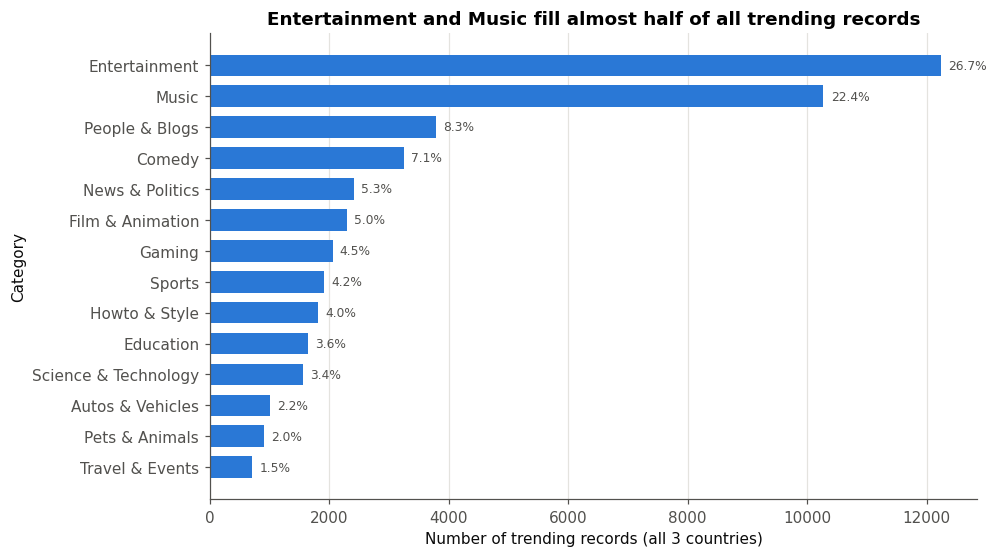

In [6]:
cat_counts = df["category_name"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(cat_counts.index, cat_counts.values, color=SEQ, height=0.7)
for y, v in enumerate(cat_counts.values):
    ax.text(v + 120, y, f"{v / cat_counts.sum():.1%}", va="center", fontsize=8, color=INK2)
ax.set_title("Entertainment and Music fill almost half of all trending records")
ax.set_xlabel("Number of trending records (all 3 countries)")
ax.set_ylabel("Category")
ax.grid(axis="y", visible=False)
save(fig, "01_records_per_category")

**Interpretation.** Entertainment (26.7% of records) and Music (22.4%) together make up almost half of all trending records. The next
category, People & Blogs, has only 8.3%, and the long tail (Travel & Events, Pets & Animals, Autos & Vehicles) has under 2.5% each. Three
categories in the lookup (Movies, Nonprofits & Activism, Shows) never trend at all, so in this data trending is concentrated in a few
broad entertainment formats.

*Why a horizontal bar chart:* category is a nominal variable and the count is a magnitude, so sorted bars compare lengths directly, and
horizontal bars leave room for the long category names.

### Chart 2 — Distribution of views (log scale)

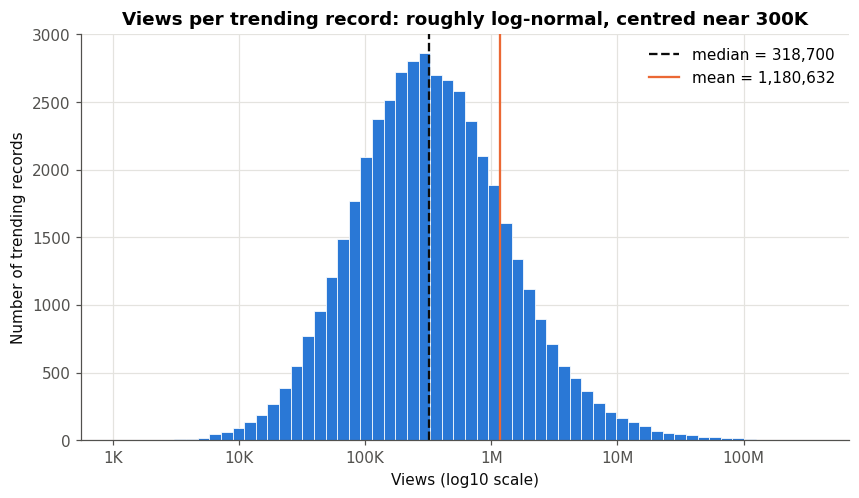

In [7]:
log_views = np.log10(df["views"])
fig, ax = plt.subplots()
ax.hist(log_views, bins=60, color=SEQ, edgecolor="white", linewidth=0.5)
ax.axvline(np.log10(df["views"].median()), color=INK, linestyle="--", linewidth=1.5, label=f"median = {df['views'].median():,.0f}")
ax.axvline(np.log10(df["views"].mean()), color=COUNTRY_COLORS["GB"], linestyle="-", linewidth=1.5, label=f"mean = {df['views'].mean():,.0f}")
ticks = [3, 4, 5, 6, 7, 8]
ax.set_xticks(ticks, ["1K", "10K", "100K", "1M", "10M", "100M"])
ax.set_title("Views per trending record: roughly log-normal, centred near 300K")
ax.set_xlabel("Views (log10 scale)")
ax.set_ylabel("Number of trending records")
ax.legend()
save(fig, "02_hist_log_views")

**Interpretation.** On a log scale, views form a single hump centred near 300K (median 318,701), from about 1K up to 360M. The
mean (1,180,632) sits far to the right of the median because a small number of huge videos pull it up. In plain numbers the distribution is
strongly right-skewed (skewness ≈ 28), which is why a log axis is needed to see its shape at all.

*Why a histogram:* views is one continuous variable and the question is about its shape, which a histogram shows. The log10 x-axis keeps
the many small records from being squashed into one bar.

### Chart 3 — Views vs likes

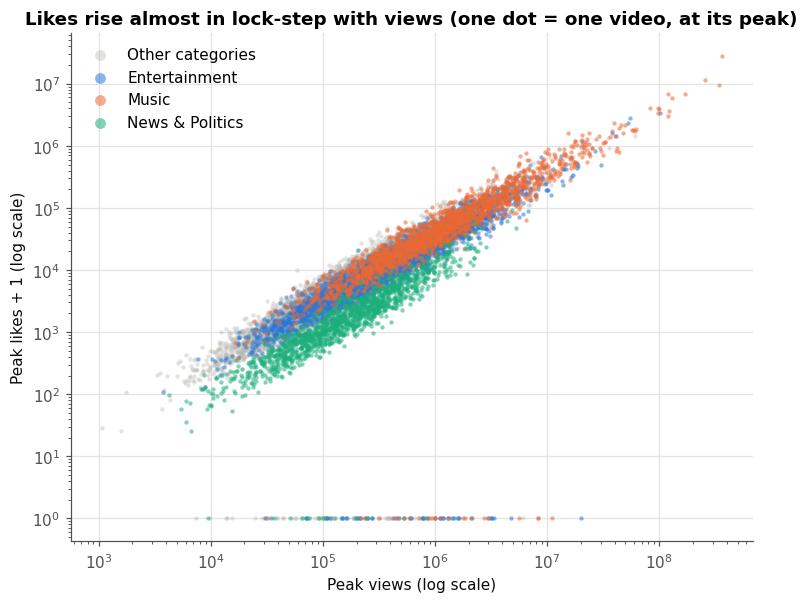

In [8]:
top3 = vids["category_name"].value_counts().index[:3].tolist()
fig, ax = plt.subplots(figsize=(8, 6))
rest = vids[~vids["category_name"].isin(top3)]
ax.scatter(rest["peak_views"], rest["peak_likes"] + 1, s=8, color=OTHER, alpha=0.4, label="Other categories", linewidths=0)
for cat, colr in zip(top3, ["#2a78d6", "#eb6834", "#1baf7a"]):
    sub = vids[vids["category_name"] == cat]
    ax.scatter(sub["peak_views"], sub["peak_likes"] + 1, s=8, color=colr, alpha=0.55, label=cat, linewidths=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Likes rise almost in lock-step with views (one dot = one video, at its peak)")
ax.set_xlabel("Peak views (log scale)")
ax.set_ylabel("Peak likes + 1 (log scale)")
ax.legend(markerscale=2.5, loc="upper left")
save(fig, "03_scatter_views_likes")

**Interpretation.** On log–log axes, likes rise almost in proportion to views, a tight upward band (correlation of the logs ≈ 0.79).
The band is not perfectly tight: at the same view count, likes can differ by about ×10. Music (blue) sits at the top right with the most
views and likes. The flat row of points at the bottom (likes + 1 = 1) is the ratings-disabled videos, whose likes are a true zero.

*Why a scatter plot:* it compares two continuous variables for each video and shows the strength and shape of their relationship. The log
scales spread out the skewed values, and the top 3 categories plus a grey "Other" keep the colours readable.

### Chart 4 — New videos entering the trending list per day

trending records per day, by country (min / max):
country     GB     IN     US
min     197.00 198.00 196.00
max     200.00 200.00 200.00


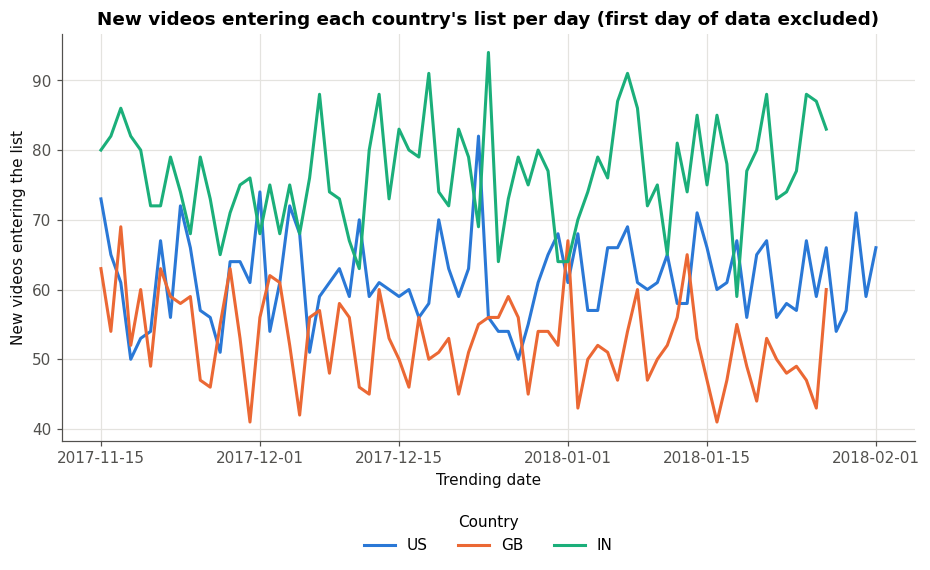

In [9]:
per_day = df.groupby(["trending_date", "country"]).size().unstack()
entrants = vids.groupby(["first_day", "country"]).size().unstack()
print("trending records per day, by country (min / max):")
print(per_day.agg(["min", "max"]))

fig, ax = plt.subplots(figsize=(10, 4.8))
for c in COUNTRIES:
    s = entrants[c].iloc[1:]           # day 1 = everything already on the list, not real "new" entrants
    ax.plot(s.index, s.values, color=COUNTRY_COLORS[c], linewidth=2, label=c)
ax.set_title("New videos entering each country's list per day (first day of data excluded)")
ax.set_xlabel("Trending date")
ax.set_ylabel("New videos entering the list")
ax.legend(title="Country", ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
save(fig, "04_line_new_entrants_per_day")

**Interpretation.** Each country's list holds a steady 196–200 records a day (printed above), so the volume of trending records is
flat by design. The real day-to-day activity is **turnover**: on average about 77 new videos enter India's list each day, 62 enter the
US list and 53 enter GB's. India's list therefore churns fastest and GB's most slowly, which matches the shorter lifespans seen for India
in section 7.

*Why a line chart:* the x-axis is time (one point per day) and lines show trend and volatility over consecutive days. With one colour per
country, the three series can be compared on the same axis.

### Chart 5 — Views by category (box plot)

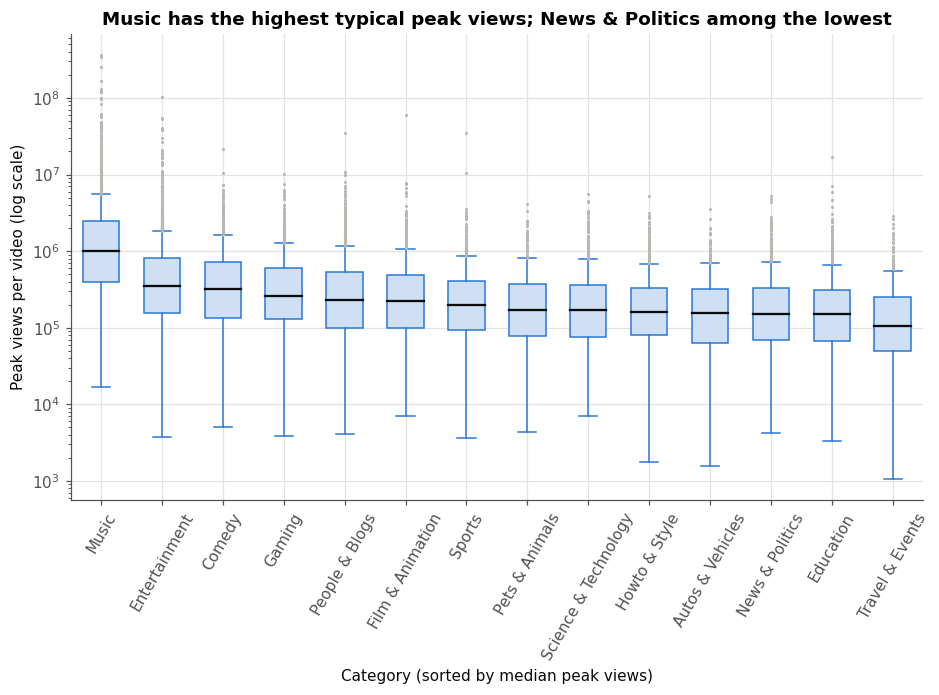

In [10]:
order = vids.groupby("category_name")["peak_views"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.boxplot([vids.loc[vids["category_name"] == c, "peak_views"] for c in order], labels=order, vert=True,
           patch_artist=True, showfliers=True, widths=0.6,
           boxprops=dict(facecolor="#cfe0f5", edgecolor=SEQ), medianprops=dict(color=INK, linewidth=1.5),
           whiskerprops=dict(color=SEQ), capprops=dict(color=SEQ),
           flierprops=dict(marker="o", markersize=2, markerfacecolor=OTHER, markeredgecolor="none"))
ax.set_yscale("log")
ax.set_title("Music has the highest typical peak views; News & Politics among the lowest")
ax.set_xlabel("Category (sorted by median peak views)")
ax.set_ylabel("Peak views per video (log scale)")
ax.tick_params(axis="x", rotation=60)
save(fig, "05_box_views_by_category")

**Interpretation.** Music's median peak views (≈ 992K) are almost three times the next category, Entertainment (≈ 350K), and its whole
box sits higher. The other categories cluster between ≈ 107K (Travel & Events) and ≈ 324K (Comedy) at the median. Every category has a long
upper tail of outliers, so the *typical* video and the *exceptional* video tell different stories.

*Why a box plot:* it compares the distribution (median, quartiles, spread and outliers) of a continuous variable across many groups at
once. The log y-axis is required because views span five orders of magnitude.

### Chart 6 — Like ratio by category

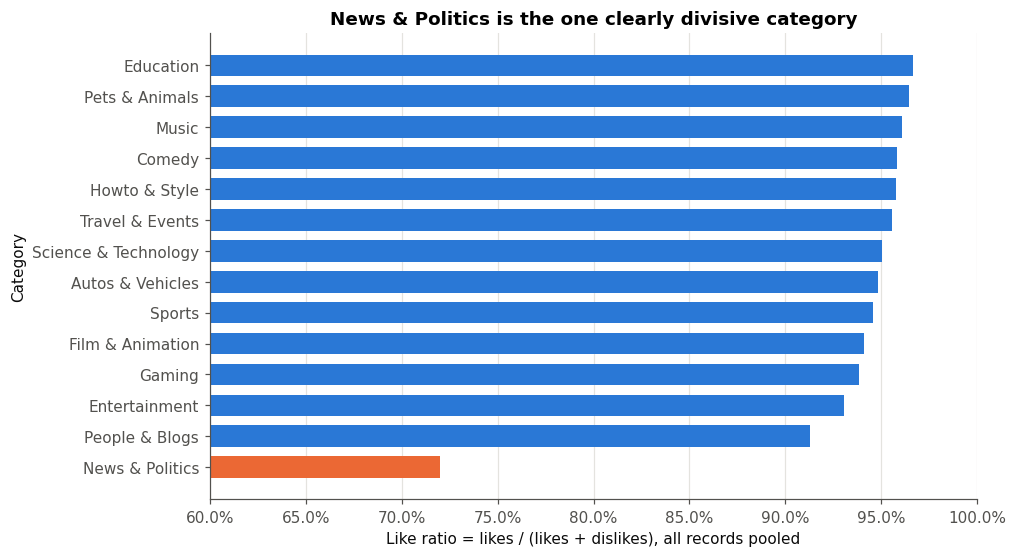

In [11]:
lr = df[(df["likes"] + df["dislikes"]) > 0]
ratio_by_cat = (lr["likes"].groupby(lr["category_name"]).sum() /
                (lr["likes"] + lr["dislikes"]).groupby(lr["category_name"]).sum()).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [COUNTRY_COLORS["GB"] if c == "News & Politics" else SEQ for c in ratio_by_cat.index]
ax.barh(ratio_by_cat.index, ratio_by_cat.values, color=colors, height=0.7)
ax.set_xlim(0.6, 1.0)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("News & Politics is the one clearly divisive category")
ax.set_xlabel("Like ratio = likes / (likes + dislikes), all records pooled")
ax.set_ylabel("Category")
ax.grid(axis="y", visible=False)
save(fig, "06_like_ratio_by_category")

**Interpretation.** Almost every category gets 91–97% likes among its votes, but News & Politics stands alone at about 72%. Roughly one
vote in four on a trending news video is a dislike. People & Blogs (91%) and Entertainment (93%) are the next lowest. News therefore
reaches the list through attention rather than approval, which fits its very short lifespan (section 7).

*Why a bar chart:* a ratio per nominal category is compared by bar length. The x-axis starts at 60% rather than zero so the 1–5 point
differences are visible; this is stated on the axis. News is highlighted in a contrasting colour because it is the finding.

## 3. Interactive charts (Plotly)

### Plotly 1 — Views vs likes by category, title on hover

In [12]:
top6 = vids["category_name"].value_counts().index[:6].tolist()
pv = vids.assign(group=np.where(vids["category_name"].isin(top6), vids["category_name"], "Other"),
                 likes_plus1=vids["peak_likes"] + 1)
fig = px.scatter(pv, x="peak_views", y="likes_plus1", color="group", log_x=True, log_y=True, opacity=0.6,
                 hover_name="title", hover_data={"country": True, "category_name": True, "peak_views": ":,",
                                                 "peak_likes": ":,", "lifespan": True, "group": False, "likes_plus1": False},
                 category_orders={"group": top6 + ["Other"]},
                 color_discrete_sequence=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6", "#b8b7b0"],
                 labels={"peak_views": "Peak views (log)", "likes_plus1": "Peak likes + 1 (log)", "group": "Category"},
                 title="Views vs likes per video — hover for title, country and lifespan; click legend to filter")
fig.update_traces(marker=dict(size=5))
fig.update_layout(template="plotly_white", height=550)
fig.write_html(f"{CHART_DIR}/p1_scatter_views_likes.html", include_plotlyjs="cdn")
fig.show()

**Interpretation.** The interactive version of Chart 3 shows the same tight views–likes band. Hovering identifies individual
videos: the far top-right points are long-running Music videos (for example, *Lena Ortiz - Monsoon (Live)* with 360M peak views and 25 days
on GB's list). Clicking News & Politics in the legend isolates it: those points sit *below* the main band, with fewer likes for the same
views, consistent with its low like ratio.

*Why an interactive scatter:* with about 15,000 videos, hover-for-title and click-to-filter let a reader find specific videos and
categories that a static chart cannot label. The log axes again handle the skew.

### Plotly 2 — Average views per category across countries

In [13]:
avg = (vids.groupby(["category_name", "country"])["peak_views"].mean().reset_index())
cat_order = avg.groupby("category_name")["peak_views"].mean().sort_values(ascending=False).index.tolist()
fig = px.bar(avg, x="category_name", y="peak_views", color="country", barmode="group",
             category_orders={"category_name": cat_order, "country": COUNTRIES},
             color_discrete_map=COUNTRY_COLORS,
             labels={"category_name": "Category", "peak_views": "Average peak views per video", "country": "Country"},
             title="Average peak views per video, by category and country")
fig.update_layout(template="plotly_white", height=500, xaxis_tickangle=-45, yaxis_tickformat=",.2s")
fig.write_html(f"{CHART_DIR}/p2_bar_avg_views_country.html", include_plotlyjs="cdn")
fig.show()

In [14]:
avg.pivot(index="category_name", columns="country", values="peak_views").loc[cat_order, COUNTRIES].round(0).head(6)

country,US,GB,IN
category_name,,,
Music,"3,400,120.00","4,566,668.00","2,772,721.00"
Entertainment,"900,668.00","835,107.00","944,468.00"
Comedy,"624,551.00","530,393.00","752,591.00"
Film & Animation,"418,375.00","633,235.00","532,793.00"
Gaming,"482,581.00","485,410.00","614,842.00"
People & Blogs,"560,251.00","452,495.00","556,127.00"


**Interpretation.** Music has the highest average peak views in every country, and the gap is largest in GB (≈ 4.57M vs 3.40M in the
US and 2.77M in IN). Below Music the countries are close, but India's videos average higher in several categories (Comedy ≈ 753K vs 624K in
the US, Gaming ≈ 615K vs 483K). So GB is the most Music-driven market, while India's views are spread across more categories.

*Why a grouped bar chart:* it compares a numeric measure across two nominal variables (category × country). Grouping the three country bars
inside each category makes the within-category country comparison immediate. Hover gives the exact values.

## 4. Distributions and outliers

Computed on all clean trending records. The exact mode of a count with ~46,000 distinct values is not informative (most values occur
once), so next to the exact mode I also report the **binned mode**: the midpoint of the most common bin of a 50-bin histogram on the
log scale.

In [15]:
def describe_center(s):
    exact_mode = s.mode()
    counts, edges = np.histogram(np.log10(s + 1), bins=50)
    k = counts.argmax()
    binned_mode = 10 ** ((edges[k] + edges[k + 1]) / 2) - 1
    return pd.Series({"mean": s.mean(), "median": s.median(),
                      "exact mode": exact_mode.iat[0], "times exact mode occurs": (s == exact_mode.iat[0]).sum(),
                      "binned mode": binned_mode, "skewness": s.skew()})

center = pd.DataFrame({"views": describe_center(df["views"]), "likes": describe_center(df["likes"])})
center

,views,likes
mean,"1,180,631.71","45,886.96"
median,"318,700.50","10,215.50"
exact mode,"16,000.00",0.00
times exact mode occurs,3.00,539.00
binned mode,"254,481.37","8,772.29"
skewness,27.93,44.47


**Skewness conclusion.**
* **Views:** mean 1,180,632 > median 318,701 > binned mode ≈ 254,000. Mean > median > mode is the signature of a **right-skewed**
  distribution (skewness ≈ 28): most records sit in the hundreds of thousands, and a long tail of very large videos pulls the mean up.
  The exact mode (16,000, occurring only 3 times) is meaningless for an almost-unique count, which is why the binned mode is used.
* **Likes:** mean 45,887 > median 10,216 > binned mode ≈ 8,800, so also **right-skewed** (skewness ≈ 44). The exact mode is **0**
  (539 records): every one of them is a ratings-disabled video, a genuine zero rather than a typical value.

In [16]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = (s < lo) | (s > hi)
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "lower fence": lo, "upper fence": hi,
                      "outliers": out.sum(), "outliers %": out.mean() * 100,
                      "outliers on log10 scale": iqr_count_log(s)})

def iqr_count_log(s):
    l = np.log10(s + 1)
    q1, q3 = l.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((l < q1 - 1.5 * iqr) | (l > q3 + 1.5 * iqr)).sum()

pd.DataFrame({"views": iqr_outliers(df["views"]), "likes": iqr_outliers(df["likes"])})

,views,likes
Q1,"129,621.75","3,657.75"
Q3,"823,817.00","28,987.25"
IQR,"694,195.25","25,329.50"
lower fence,"-911,671.12","-34,336.50"
upper fence,"1,865,109.88","66,981.50"
outliers,"5,068.00","5,249.00"
outliers %,11.05,11.45
outliers on log10 scale,617.00,"1,039.00"


**IQR outliers.**
* **Views:** Q1 = 129,622, Q3 = 823,817, IQR = 694,195. The upper fence is 1,865,110 (the lower fence is negative, so there are no low
  outliers). **5,068 records (11.1%)** are outliers.
* **Likes:** upper fence 66,982, giving **5,249 records (11.4%)** as outliers.

**Decision: keep them.** These are not errors (no impossible values, and duplicates and removed videos were already dropped). They are the
very hits this analysis is about: removing them would delete most of Music and every long-running video. The IQR rule flags so much
because it assumes a roughly symmetric distribution. On the log scale, where views are close to symmetric, only 617 records (views) and
1,039 (likes) fall outside the fences. For averages I therefore report medians next to means, and I use log scales in the charts,
instead of deleting data.

## 5. Correlation

Pearson correlation across the record-level numeric columns, plus the like ratio. I also show the Spearman (rank) version, which is less
sensitive to the huge outliers found above.

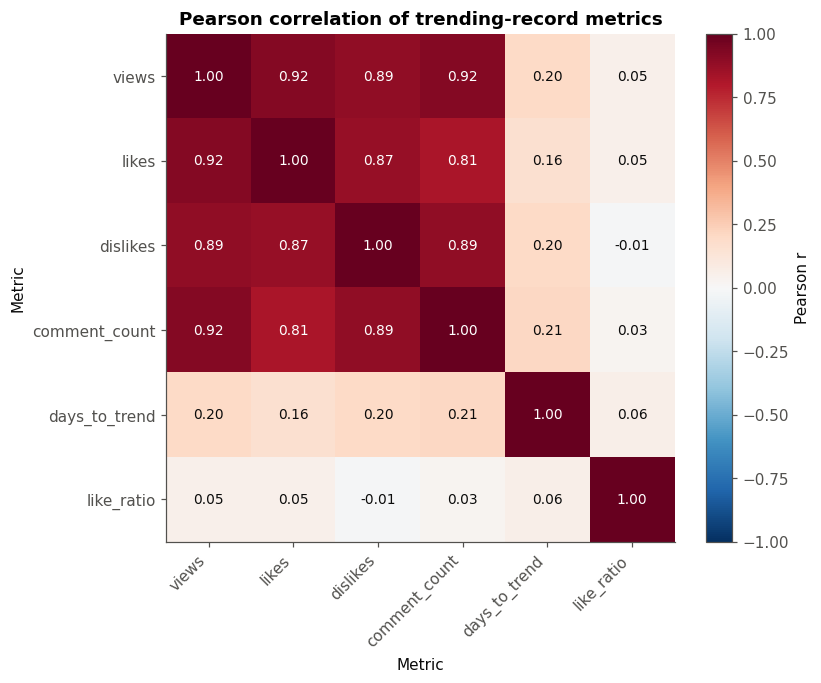

pearson  spearman
views    likes             0.92      0.92
         comment_count     0.92      0.87
dislikes comment_count     0.89      0.79
views    dislikes          0.89      0.86
likes    dislikes          0.87      0.89
         comment_count     0.81      0.78

In [17]:
num = df[["views", "likes", "dislikes", "comment_count", "days_to_trend"]].copy()
votes = df["likes"] + df["dislikes"]
num["like_ratio"] = np.where(votes > 0, df["likes"] / votes.where(votes > 0), np.nan)
corr = num.corr()
spearman = num.corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else INK)
ax.grid(False)
ax.set_title("Pearson correlation of trending-record metrics")
ax.set_xlabel("Metric"); ax.set_ylabel("Metric")
fig.colorbar(im, ax=ax, label="Pearson r")
save(fig, "07_correlation_heatmap")

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("pearson").to_frame())
pairs["spearman"] = spearman.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs.reindex(pairs["pearson"].abs().sort_values(ascending=False).index)
pairs.head(6)

**The two strongest correlations** (largest absolute off-diagonal Pearson coefficients):
1. **views – likes: r = 0.92.** Videos with more views collect proportionally more likes, because likes come from viewers and grow with reach.
2. **views – comment_count: r = 0.92 (0.916).** Comments also scale with audience size. The audience count drives every engagement count,
   which is why the count columns all correlate 0.81–0.92 with each other.

By contrast, **like_ratio** is almost uncorrelated with views (r ≈ 0.05). How *well liked* a video is says nothing about how *big* it
is. **days_to_trend** is only weakly positive (≈ 0.2), because a video that has been out longer has had more time to collect views.

**Correlation is not causation:** likes and views move together because both are driven by the same thing, the size of the audience
reached (a third variable). Likes are a *result* of viewing, so this data cannot show that adding likes would cause more views.

## 6. Funnel analysis

One row per **unique video** (`video_id`, combining countries): its peak views and peak comments across all its trending days and
countries. Each stage is a subset of the previous one.

In [18]:
u = df.groupby("video_id").agg(peak_views=("views", "max"), peak_comments=("comment_count", "max")).reset_index()
med, p90 = u["peak_views"].median(), u["peak_views"].quantile(0.90)
s1 = u
s2 = s1[s1["peak_views"] > med]
s3 = s2[s2["peak_views"] > p90]
s4 = s3[s3["peak_comments"] >= 1000]
stages = pd.DataFrame({
    "stage": ["1. Ever trended", f"2. Peak views > median ({med:,.0f})", f"3. Peak views > 90th pct ({p90:,.0f})",
              "4. ... and 1,000+ comments"],
    "videos": [len(s1), len(s2), len(s3), len(s4)]})
stages["conversion from previous"] = (stages["videos"] / stages["videos"].shift(1) * 100).round(1)
stages["conversion from start"] = (stages["videos"] / len(s1) * 100).round(1)
stages["drop-off (videos lost)"] = (stages["videos"].shift(1) - stages["videos"]).fillna(0).astype(int)
stages

,stage,videos,conversion from previous,conversion from start,drop-off (videos lost)
0,1. Ever trended,14684,NaN,100.00,0
1,"2. Peak views > median (265,290)",7342,50.00,50.00,7342
2,"3. Peak views > 90th pct (1,646,274)",1469,20.00,10.00,5873
3,"4. ... and 1,000+ comments",1440,98.00,9.80,29


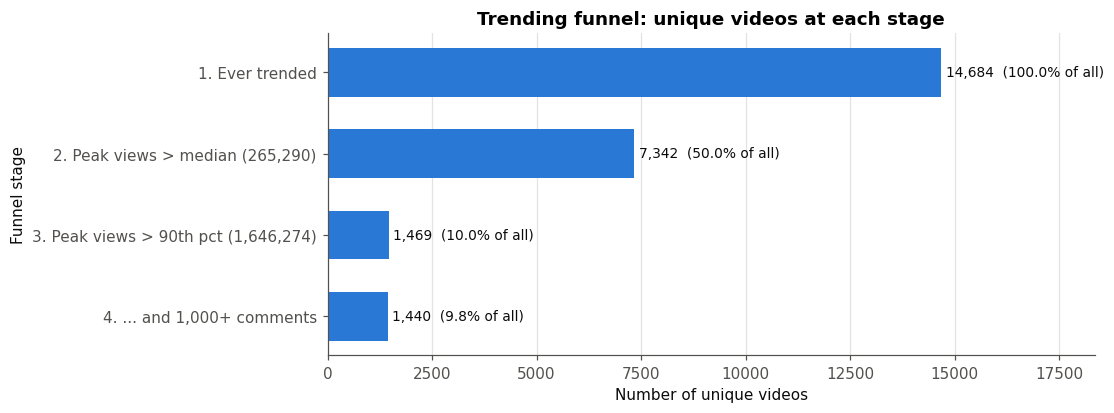

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(stages["stage"][::-1], stages["videos"][::-1], color=SEQ, height=0.6)
for y, (v, c) in enumerate(zip(stages["videos"][::-1], stages["conversion from start"][::-1])):
    ax.text(v + 100, y, f"{v:,}  ({c:.1f}% of all)", va="center", fontsize=9, color=INK)
ax.set_title("Trending funnel: unique videos at each stage")
ax.set_xlabel("Number of unique videos"); ax.set_ylabel("Funnel stage")
ax.set_xlim(0, len(s1) * 1.25); ax.grid(axis="y", visible=False)
save(fig, "08_funnel")

**Funnel result**

| Stage | Unique videos | Conversion from previous | Conversion from start |
|---|---|---|---|
| 1. Ever trended | 14,684 | — | 100% |
| 2. Peak views > median (265,290) | 7,342 | 50.0% | 50.0% |
| 3. Peak views > 90th percentile (1,646,274) | 1,469 | 20.0% | 10.0% |
| 4. ... and 1,000+ comments | 1,440 | 98.0% | 9.8% |

**Largest drop-off: stage 2 → 3.** Only 20% of above-median videos make it into the top 10%, so 5,873 videos are lost. Stage 1 → 2 is
50% by construction, since the median splits the group in half. This means that reaching the trending list is common, but breaking out
to the top 10% is the real filter: views are so skewed that the 90th percentile (1.65M) is more than six times the median. Once a video
*is* that big, 1,000+ comments is almost automatic (98%), so for the biggest videos comment volume follows reach rather than being a
separate hurdle.

## 7. Retention-style analysis (trending lifespan)

Day 1 = a video's first trending day in a country. A video is "retained on day *k*" if it is on that country's list on day
first_day + (k − 1).

**Right-censoring:** a video that first trends in the last few days of the window cannot be observed on day 7. So only videos whose
first trending day is at least 6 days before that country's last day are included. Videos already on the list on the very first day of
the data are also excluded, since their real first day is unknown.

In [20]:
on_list = set(zip(df["country"], df["video_id"], df["trending_date"]))
bounds = df.groupby("country")["trending_date"].agg(["min", "max"])
DAYS = list(range(1, 11))

eligible = vids[(vids["first_day"] > vids["country"].map(bounds["min"])) &
                (vids["first_day"] <= vids["country"].map(bounds["max"]) - pd.Timedelta(days=6))].copy()
for k in DAYS:
    offset = pd.Timedelta(days=k - 1)
    eligible[f"d{k}"] = [(c, v, f + offset) in on_list for c, v, f in
                         zip(eligible["country"], eligible["video_id"], eligible["first_day"])]

def retention(frame):
    return pd.Series({f"day {k}": frame[f"d{k}"].mean() * 100 for k in DAYS})

print(f"videos in the retention analysis: {len(eligible):,} of {len(vids):,}")
overall = retention(eligible)
overall.loc[["day 2", "day 3", "day 5", "day 7"]].round(1).to_frame("% still trending")

videos in the retention analysis: 13,294 of 15,043


,% still trending
day 2,63.80
day 3,42.70
day 5,20.20
day 7,10.40


In [21]:
groups = {
    "All videos": eligible,
    "Music": eligible[eligible["category_name"] == "Music"],
    "Entertainment": eligible[eligible["category_name"] == "Entertainment"],
    "News & Politics": eligible[eligible["category_name"] == "News & Politics"],
}
ret_cat = pd.DataFrame({g: retention(f) for g, f in groups.items()}).T
ret_cat.insert(0, "videos", [len(f) for f in groups.values()])
ret_country = pd.DataFrame({c: retention(eligible[eligible["country"] == c]) for c in COUNTRIES}).T
ret_country.insert(0, "videos", eligible["country"].value_counts()[COUNTRIES].values)
show = ["videos", "day 2", "day 3", "day 5", "day 7"]
print("By category (% still trending)"); display(ret_cat[show].round(1))
print("By country (% still trending)"); display(ret_country[show].round(1))

By category (% still trending)


,videos,day 2,day 3,day 5,day 7
All videos,13294,63.80,42.70,20.20,10.40
Music,1706,81.20,66.00,44.70,30.60
Entertainment,3073,71.00,52.50,28.10,14.40
News & Politics,1232,41.10,16.20,3.80,1.00


By country (% still trending)


,videos,day 2,day 3,day 5,day 7
US,4492,65.80,44.70,21.10,11.50
GB,3615,69.70,50.10,27.10,15.10
IN,5187,57.80,35.80,14.60,6.10


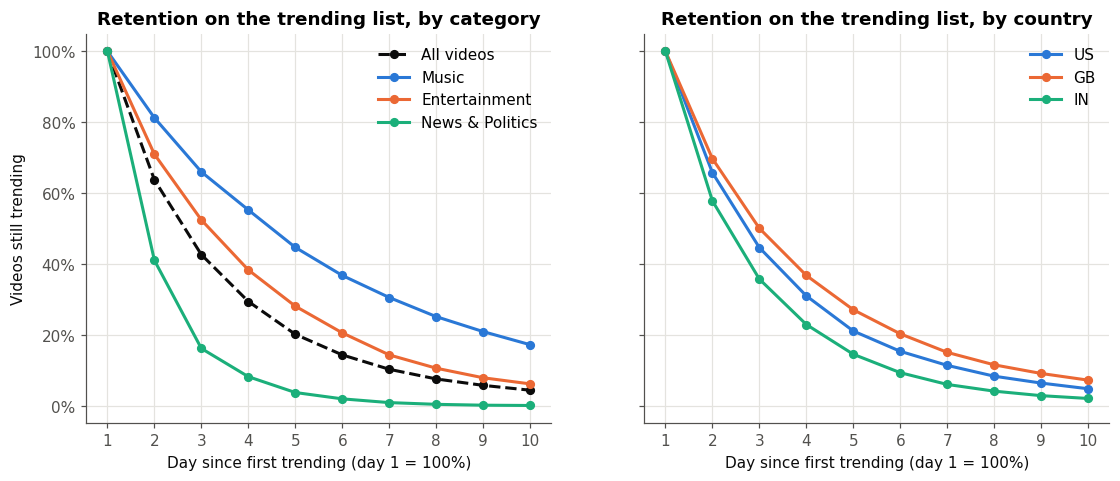

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
cat_colors = {"All videos": INK, "Music": "#2a78d6", "Entertainment": "#eb6834", "News & Politics": "#1baf7a"}
for g in ret_cat.index:
    axes[0].plot(DAYS, ret_cat.loc[g, [f"day {k}" for k in DAYS]], marker="o", markersize=5,
                 linewidth=2, color=cat_colors[g], linestyle="--" if g == "All videos" else "-", label=g)
for c in COUNTRIES:
    axes[1].plot(DAYS, ret_country.loc[c, [f"day {k}" for k in DAYS]], marker="o", markersize=5,
                 linewidth=2, color=COUNTRY_COLORS[c], label=c)
for ax, t in zip(axes, ["by category", "by country"]):
    ax.set_title(f"Retention on the trending list, {t}")
    ax.set_xlabel("Day since first trending (day 1 = 100%)")
    ax.set_xticks(DAYS)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(100))
    ax.legend()
axes[0].set_ylabel("Videos still trending")
save(fig, "09_retention_curves")

**Retention result** (13,294 videos; % still on the list):

| Group | Day 2 | Day 3 | Day 5 | Day 7 |
|---|---|---|---|---|
| **All videos** | **63.8%** | **42.7%** | **20.2%** | **10.4%** |
| Music | 81.2% | 66.0% | 44.7% | 30.6% |
| Entertainment | 71.0% | 52.5% | 28.1% | 14.4% |
| News & Politics | 41.1% | 16.2% | 3.8% | 1.0% |
| US | 65.8% | 44.7% | 21.1% | 11.5% |
| GB | 69.7% | 50.1% | 27.1% | 15.1% |
| IN | 57.8% | 35.8% | 14.6% | 6.1% |

**Interpretation.** About a third of videos (36%) disappear after a single day, and only one in ten is still trending a week later.
**Music stays:** almost a third of Music videos are still on the list on day 7, three times the overall rate. **News & Politics
vanishes:** 59% are gone after day 1 and only 1% reach day 7, the pattern of a one-day news spike. Among countries, GB keeps videos
longest (15.1% on day 7) and India shortest (6.1%), consistent with India's faster daily turnover (Chart 4).

*Why a line chart for retention:* day number is ordered and the measure is a share that can only fall, so a curve per group shows both the
level and the speed of decay, and where the groups diverge.

## 8. Cohort view

Videos are grouped by the **ISO week in which they first trended** (per country). Metrics: number of videos, average lifespan, and
median peak views (median, so one huge video cannot drive a cohort).

In [23]:
vids["cohort_week"] = vids["first_day"].dt.to_period("W-SUN").dt.start_time
cohorts = (vids.groupby("cohort_week")
             .agg(videos=("video_id", "size"), avg_lifespan=("lifespan", "mean"),
                  median_peak_views=("peak_views", "median"), days_observed=("first_day", "nunique"))
             .reset_index())
cohorts["cohort_week"] = cohorts["cohort_week"].dt.date
cohorts

,cohort_week,videos,avg_lifespan,median_peak_views,days_observed
0,2017-11-13,1607,3.20,"266,286.00",6
1,2017-11-20,1326,3.19,"269,650.50",7
2,2017-11-27,1318,3.11,"260,651.50",7
3,2017-12-04,1323,3.23,"275,461.00",7
4,2017-12-11,1327,3.08,"271,502.00",7
5,2017-12-18,1374,3.15,"269,018.50",7
6,2017-12-25,1295,3.14,"273,822.00",7
7,2018-01-01,1349,3.12,"245,696.00",7
8,2018-01-08,1355,3.14,"281,822.00",7
9,2018-01-15,1320,3.01,"266,344.50",7


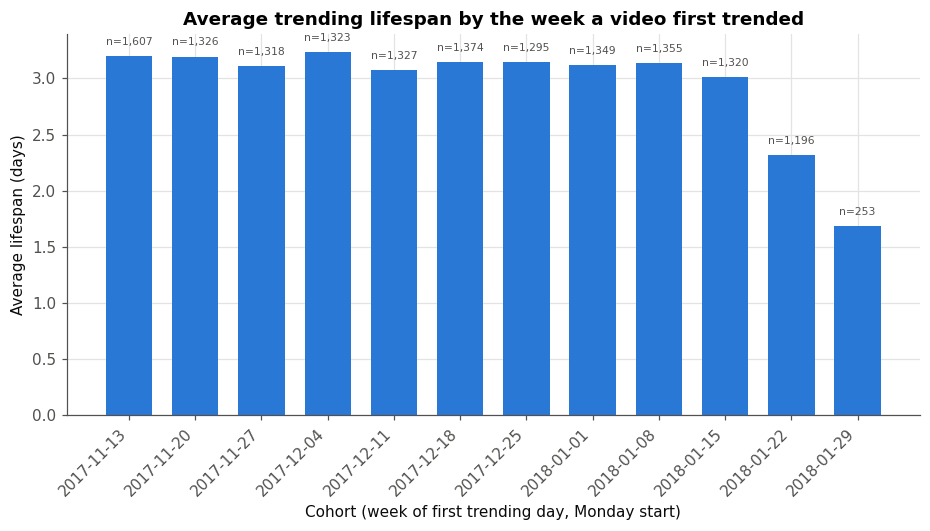

In [24]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(cohorts))
ax.bar(x, cohorts["avg_lifespan"], color=SEQ, width=0.7)
for i, (v, n_) in enumerate(zip(cohorts["avg_lifespan"], cohorts["videos"])):
    ax.text(i, v + 0.1, f"n={n_:,}", ha="center", fontsize=7, color=INK2)
ax.set_xticks(x, [str(d) for d in cohorts["cohort_week"]], rotation=45, ha="right")
ax.set_title("Average trending lifespan by the week a video first trended")
ax.set_xlabel("Cohort (week of first trending day, Monday start)")
ax.set_ylabel("Average lifespan (days)")
save(fig, "10_cohort_lifespan")

**Cohort conclusion.** The first ten weekly cohorts are remarkably similar: an average lifespan of 3.0–3.2 days and a median
peak of ≈ 246K–282K views. Two cohorts look different, and **both differences are explained by the amount of data, not by behaviour**:
* **Week of 2018-01-22 (2.32 days)** and **week of 2018-01-29 (1.69 days, only 253 videos and 4 observed days):** these videos first
  trended near the end of the window, so the data stops before many of them leave the list. Their lifespans (and their peak views,
  174K) are cut off (**right-censored**), not genuinely shorter.
* **Week of 2017-11-13 (1,607 videos, the most):** day 1 of the data counts every video already on the list as a "new" entrant, so this
  cohort is inflated by videos that actually started trending earlier (**left-censored**).

So there is no real trend across cohorts. A fair cohort comparison should drop the first and last two weeks, or, as in section 7,
only use videos that can be observed for the full period being measured.

## 9. Content strategy briefing

### Briefing for the content team

Trending is dominated by two formats: **Entertainment (26.7%) and Music (22.4%) fill almost half of all trending slots** across the US, GB
and India. Music is also the strongest performer, with a median peak of ≈ 990K views, nearly three times any other category. Videos get there
fast: **the median video trends 1 day after publishing, 41% trend the same day and 63% within a day**, so a video's first 24–48 hours
decide whether it trends. What separates videos that stay from those that vanish is format and audience approval. **About 36% of videos
drop off after one day and only 10% last a week, but 31% of Music videos are still trending on day 7, against 1% of News & Politics videos**,
which also have the lowest like ratio (≈ 72% vs 91–97% elsewhere). Countries differ clearly: **GB is the most Music-heavy market (33% of
its records) and keeps videos longest (15% still trending on day 7)**, while **India leans to Entertainment (34%) and News, and churns
fastest** (≈ 77 new entrants a day, 6% still trending on day 7). The practical takeaway is to invest in repeat-value formats (music and
entertainment) for lasting trending presence, and to treat news content as a one-day reach play. **Limitation:** this data contains only
videos that *did* trend, over a fixed ~11-week window (Nov 2017 – Jan 2018), so it cannot show what makes a video fail to trend, and
lifespans at the edges of the window are censored. (The copy of the files used here is also documented by its provider as a synthetic
reproduction of the Kaggle dataset, so the figures should be re-checked on the real files before acting on them.)